# look at the distance of airport guess and make a graph of correcntess to sfdps. 

In [42]:
from datetime import date
import polars as pl
from data_engineering.adsb.read_adsb import read_adsb
from data_engineering.adsbx.get_flights import get_adsbx_flights_for_day
from data_engineering.bts.read_bts_ontime_to_flights import get_bts_flights_for_day
from data_engineering.flights.sfdps_to_flights import get_sfdps_flights_day
from flights.flights_match_adsb import flights_match_adsb, get_matching_icaos_in_flights

test_date = date(2026,3,1)
df_model = pl.read_parquet('/Volumes/T2-SSD/planequery/data/flights/trad-model/v2/flights.parquet')
df_sfdps = get_sfdps_flights_day(test_date)
df_sfdps = get_matching_icaos_in_flights(df_sfdps, read_adsb(test_date))
expr = pl.col("takeoff_time").dt.date() == test_date 
df_sfdps = df_sfdps.filter(expr)
df_model = df_model.filter(expr)
df_model = df_model.filter(pl.col("icao").is_in(df_sfdps.get_column("icao").unique().implode()))

In [44]:
from flights.flights_comparison import df_flights_comparision, df_flights_comparison_stats, flights_comparison
from datetime import datetime, time
start_dt = datetime.combine(test_date, time.min)
end_dt = datetime.combine(test_date, time.max)
df = df_flights_comparision(df_model, df_sfdps, start_dt=start_dt, end_dt=end_dt, compare_airports=False)
stats = df_flights_comparison_stats(df)
print(stats)

{'true_positive': 7571, 'false_positive': 319, 'false_negative': 177, 'precision': 0.9595690747782003, 'recall': 0.9771553949406299, 'f1': 0.9682823890523086, 'airport_ident_match_pct': 0.9229956412627129}


In [45]:
COLUMNS = [
    "icao",
    "takeoff_time",
    "takeoff_airport_ident",
    "takeoff_airport_ident_distance_km",
    "landing_time",
    "landing_airport_ident",
    "landing_airport_ident_distance_km",
    "takeoff_time_df1",
    "takeoff_airport_ident_df1",
    "landing_time_df1",
    "landing_airport_ident_df1",
    "same_takeoff_airport_ident",
    "same_landing_airport_ident",
    "same_airport_ident",
    "match_status",
]
df = df.select(COLUMNS)

In [46]:
df = df.filter(
    (pl.col("match_status") == "both").all().over("icao")
)

In [47]:
df.filter(pl.col("same_landing_airport_ident") == False).filter(pl.col("landing_airport_ident_distance_km") > 10)

icao,takeoff_time,takeoff_airport_ident,takeoff_airport_ident_distance_km,landing_time,landing_airport_ident,landing_airport_ident_distance_km,takeoff_time_df1,takeoff_airport_ident_df1,landing_time_df1,landing_airport_ident_df1,same_takeoff_airport_ident,same_landing_airport_ident,same_airport_ident,match_status
str,datetime[ms],str,f64,datetime[ms],str,f64,datetime[ms],str,datetime[ms],str,bool,bool,bool,str
"""a099fd""",2026-03-01 15:07:12.011,"""KFXE""",0.23145,2026-03-01 18:37:08.040,"""TNCM""",37.836662,2026-03-01 15:07:00,"""KFXE""",2026-03-01 18:55:00,"""TQPF""",true,false,false,"""both"""
"""a19634""",2026-03-01 14:23:27.064,"""KXBP""",1.565295,2026-03-01 16:22:11.260,"""KELD""",30.703875,2026-03-01 14:27:00,"""KXBP""",2026-03-01 16:50:00,"""KBQP""",true,false,false,"""both"""
"""a1cb2d""",2026-03-01 15:38:58.938,"""KMRH""",2.208004,2026-03-01 17:32:09.501,"""SC15""",14.092061,2026-03-01 15:41:00,"""KMRH""",2026-03-01 17:38:00,"""ARW""",true,false,false,"""both"""
"""a1df50""",2026-03-01 14:41:12.951,"""KPMP""",0.18504,2026-03-01 18:32:55.349,"""TNCM""",37.668779,2026-03-01 14:41:00,"""KPMP""",2026-03-01 18:53:00,"""TQPF""",true,false,false,"""both"""
"""a37e7b""",2026-03-01 16:44:53.205,"""KAPA""",0.268134,2026-03-01 19:23:21.931,"""KBQP""",20.329767,2026-03-01 16:52:00,"""KAPA""",2026-03-01 19:36:00,"""KMLU""",true,false,false,"""both"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ab7d82""",2026-03-01 10:30:28.260,"""KPVG""",4.277163,2026-03-01 12:48:33.787,"""KNBC""",13.813043,2026-03-01 10:29:00,"""KPVG""",2026-03-01 13:13:00,"""KHXD""",true,false,false,"""both"""
"""ac67fc""",2026-03-01 18:43:41.518,"""KMIA""",0.939574,2026-03-01 19:46:49.060,"""MYMM""",58.43478,2026-03-01 18:44:00,"""KMIA""",2026-03-01 20:07:00,"""MBPV""",true,false,false,"""both"""
"""ac9db8""",2026-03-01 17:41:35.639,"""KAPA""",0.262779,2026-03-01 23:15:27.336,"""KSAN""",10.350186,2026-03-01 17:49:00,"""KAPA""",2026-03-01 23:18:00,"""MYF""",true,false,false,"""both"""


In [50]:
df.filter(pl.col("icao") == "acbea2")

icao,takeoff_time,takeoff_airport_ident,takeoff_airport_ident_distance_km,landing_time,landing_airport_ident,landing_airport_ident_distance_km,takeoff_time_df1,takeoff_airport_ident_df1,landing_time_df1,landing_airport_ident_df1,same_takeoff_airport_ident,same_landing_airport_ident,same_airport_ident,match_status
str,datetime[ms],str,f64,datetime[ms],str,f64,datetime[ms],str,datetime[ms],str,bool,bool,bool,str
"""acbea2""",2026-03-01 12:10:28.882,"""KBIS""",1.074635,2026-03-01 13:30:11.222,"""KDEN""",3.125924,2026-03-01 12:10:00,"""KBIS""",2026-03-01 13:32:00,"""KDEN""",true,true,true,"""both"""
"""acbea2""",2026-03-01 14:43:45.633,"""KDEN""",2.014933,2026-03-01 16:14:51.526,"""0ND0""",10.411376,2026-03-01 14:50:00,"""KDEN""",2026-03-01 16:31:00,"""KDVL""",true,false,false,"""both"""
"""acbea2""",2026-03-01 17:23:48.222,"""NA06""",12.137608,2026-03-01 19:10:35.633,"""KDEN""",3.373652,2026-03-01 17:28:00,"""KDVL""",2026-03-01 19:12:00,"""KDEN""",false,true,false,"""both"""
"""acbea2""",2026-03-01 21:06:54.995,"""KDEN""",2.057295,2026-03-01 22:19:22.021,"""KDIK""",30.175103,2026-03-01 21:13:00,"""KDEN""",2026-03-01 22:34:00,"""KDIK""",true,true,true,"""both"""


In [49]:
df.filter(pl.col("landing_airport_ident") == "KBQP")

icao,takeoff_time,takeoff_airport_ident,takeoff_airport_ident_distance_km,landing_time,landing_airport_ident,landing_airport_ident_distance_km,takeoff_time_df1,takeoff_airport_ident_df1,landing_time_df1,landing_airport_ident_df1,same_takeoff_airport_ident,same_landing_airport_ident,same_airport_ident,match_status
str,datetime[ms],str,f64,datetime[ms],str,f64,datetime[ms],str,datetime[ms],str,bool,bool,bool,str
"""a37e7b""",2026-03-01 16:44:53.205,"""KAPA""",0.268134,2026-03-01 19:23:21.931,"""KBQP""",20.329767,2026-03-01 16:52:00,"""KAPA""",2026-03-01 19:36:00,"""KMLU""",true,false,false,"""both"""


In [ ]:
df.filter(pl.col("same_takeoff_airport_ident") == False)

airport_ident,distance_bin_start_km,total_airport_idents,disagreeing_airport_idents,distance_bin_end_km,disagreement_pct
str,i64,u32,u32,i64,f64
"""landing_airport_ident""",0,25931,2003,10,7.724345
"""takeoff_airport_ident""",0,25900,1041,10,4.019305
"""landing_airport_ident""",10,129,76,20,58.914729
"""takeoff_airport_ident""",10,153,82,20,53.594771
"""landing_airport_ident""",20,32,14,30,43.75
…,…,…,…,…,…
"""takeoff_airport_ident""",40,8,8,50,100.0
"""landing_airport_ident""",50,1,1,60,100.0
"""takeoff_airport_ident""",50,2,2,60,100.0


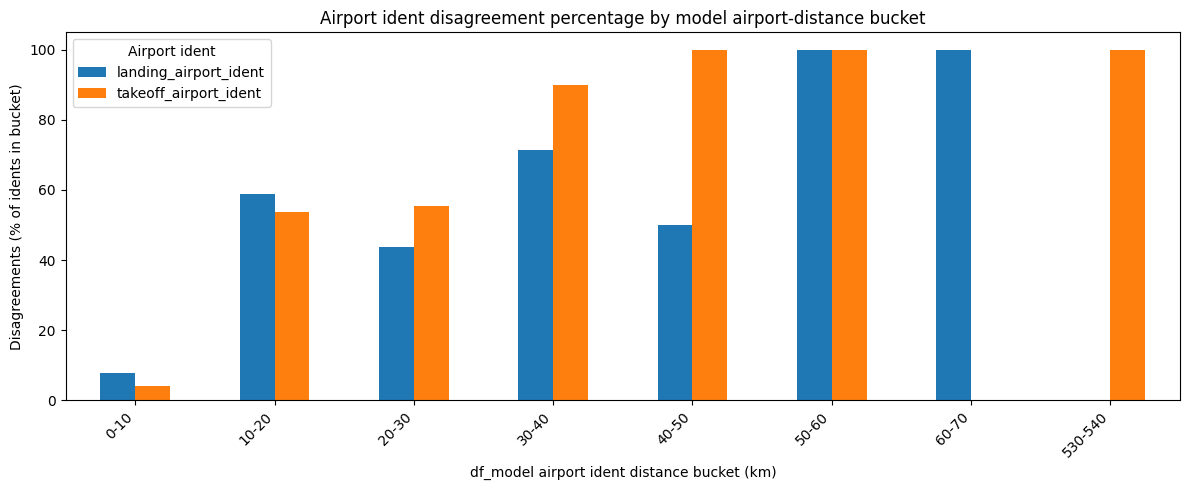

In [19]:
import matplotlib.pyplot as plt

DISTANCE_BIN_KM = 10

matched_flights = df.filter(pl.col("match_status") == "both")

airport_distance_buckets = (
    matched_flights
    .select(
        pl.col("takeoff_airport_ident_distance_km").alias("takeoff_airport_ident"),
        pl.col("landing_airport_ident_distance_km").alias("landing_airport_ident"),
        (~pl.col("same_takeoff_airport_ident")).alias("takeoff_airport_ident_disagrees"),
        (~pl.col("same_landing_airport_ident")).alias("landing_airport_ident_disagrees"),
    )
    .unpivot(
        index=["takeoff_airport_ident_disagrees", "landing_airport_ident_disagrees"],
        variable_name="airport_ident",
        value_name="distance_km",
    )
    .with_columns(
        pl.when(pl.col("airport_ident") == "takeoff_airport_ident")
        .then(pl.col("takeoff_airport_ident_disagrees"))
        .otherwise(pl.col("landing_airport_ident_disagrees"))
        .alias("disagrees")
    )
    .drop("takeoff_airport_ident_disagrees", "landing_airport_ident_disagrees")
    .filter(pl.col("distance_km").is_not_null())
    .with_columns(
        ((pl.col("distance_km") / DISTANCE_BIN_KM).floor() * DISTANCE_BIN_KM)
        .cast(pl.Int64)
        .alias("distance_bin_start_km")
    )
)

airport_distance_disagreement_pct = (
    airport_distance_buckets
    .group_by("airport_ident", "distance_bin_start_km")
    .agg(
        pl.len().alias("total_airport_idents"),
        pl.col("disagrees").sum().alias("disagreeing_airport_idents"),
    )
    .with_columns(
        (pl.col("distance_bin_start_km") + DISTANCE_BIN_KM).alias("distance_bin_end_km"),
        (pl.col("disagreeing_airport_idents") / pl.col("total_airport_idents") * 100)
        .alias("disagreement_pct"),
    )
    .sort("distance_bin_start_km", "airport_ident")
)

plot_df = airport_distance_disagreement_pct.with_columns(
    (
        pl.col("distance_bin_start_km").cast(pl.Utf8)
        + "-"
        + pl.col("distance_bin_end_km").cast(pl.Utf8)
    ).alias("distance_bin_km")
)

plot_pd = (
    plot_df.pivot(
        index="distance_bin_km",
        on="airport_ident",
        values="disagreement_pct",
    )
    .fill_null(0)
    .join(
        plot_df.select("distance_bin_km", "distance_bin_start_km").unique(),
        on="distance_bin_km",
    )
    .sort("distance_bin_start_km")
    .drop("distance_bin_start_km")
    .to_pandas()
    .set_index("distance_bin_km")
)

ax = plot_pd.plot(kind="bar", figsize=(12, 5))
ax.set_title("Airport ident disagreement percentage by model airport-distance bucket")
ax.set_xlabel("df_model airport ident distance bucket (km)")
ax.set_ylabel("Disagreements (% of idents in bucket)")
ax.legend(title="Airport ident")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

airport_distance_disagreement_pct